# Lab 7 · Example B — Reuters Topic Classification with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Why a second example?** Same ingredients (Embedding → Bidirectional LSTM → Dense), but now the
task has **46 topic classes**, not 2. This shows how the **output layer and loss change** when you
move from *binary* to *multi-class* classification. Spot the differences from Example A!

| | Example A (IMDB) | Example B (Reuters) |
|---|---|---|
| classes | 2 (pos/neg) | **46 topics** |
| output layer | `Dense(1, 'sigmoid')` | **`Dense(46, 'softmax')`** |
| loss | `binary_crossentropy` | **`sparse_categorical_crossentropy`** |

---
Replace every `None  # TODO (Qn)`. Run top to bottom. *(Downloads the Reuters dataset once.)*


## Step 0 — Imports *(given)*

In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

Reuters newswires are also pre-encoded as integer indices, each labelled with one of 46 topics.
Keep the top `num_words` words, pad to `maxlen`, and use the built-in test split.

*Hints:* keep 10000 words; pad to 200; count classes with `max(labels)+1`.


In [3]:
num_words = 10000     # TODO (Q1a): 10000
maxlen    = 200     # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) + 1   # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (8982, 200)  classes: 46


#### Quick check *(given)*

In [ ]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

## Task 2 — Build the model (multi-class head)

Same backbone as Example A, but the **output** changes for 46 classes.

*Hints:* `Embedding(num_words, 128)`; `Bidirectional(LSTM(64, return_sequences=False))`;
output is `Dense(num_classes, activation='softmax')` — one neuron per topic.


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** Compare this `model.summary()` with Example A. Which layer changed size,
and why? (Hint: look at the final Dense layer's parameter count.)

> **Your answer (Q2d):** the Dense layer grew from (128+1)×1 to (128+1)×46 because ____.


## Task 3 — Compile and train (multi-class loss)

Labels here are **integers** (0–45), not one-hot — so use **`sparse_categorical_crossentropy`**
(it one-hots internally). Optimiser `adam`, track accuracy. Train ~10 epochs, batch 64, with a
20% validation split.


In [5]:
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,   # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 62s 519ms/step - accuracy: 0.4245 - loss: 2.3526 - val_accuracy: 0.4903 - val_loss: 1.8669
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 55s 482ms/step - accuracy: 0.5314 - loss: 1.8216 - val_accuracy: 0.5576 - val_loss: 1.7582
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 79s 457ms/step - accuracy: 0.5549 - loss: 1.7488 - val_accuracy: 0.5687 - val_loss: 1.6704
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 55s 477ms/step - accuracy: 0.5878 - loss: 1.6382 - val_accuracy: 0.5826 - val_loss: 1.6631
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 50s 444ms/step - accuracy: 0.5566 - loss: 1.6757 - val_accuracy: 0.5637 - val_loss: 1.6562
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 50s 446ms/step - accuracy: 0.6199 - loss: 1.4511 - val_accuracy: 0.6105 - val_loss: 1.5379
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 80s 432ms/step - accuracy: 0.6657 - loss: 1.2855 - val_accuracy: 0.6132 - val_loss: 1.5376
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 53s 468ms/step - accuracy: 0.6981 - loss: 1

## Task 4 — Evaluate and plot *(fill the blanks)*

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - accuracy: 0.6211 - loss: 1.6378
Test accuracy: 62.11%


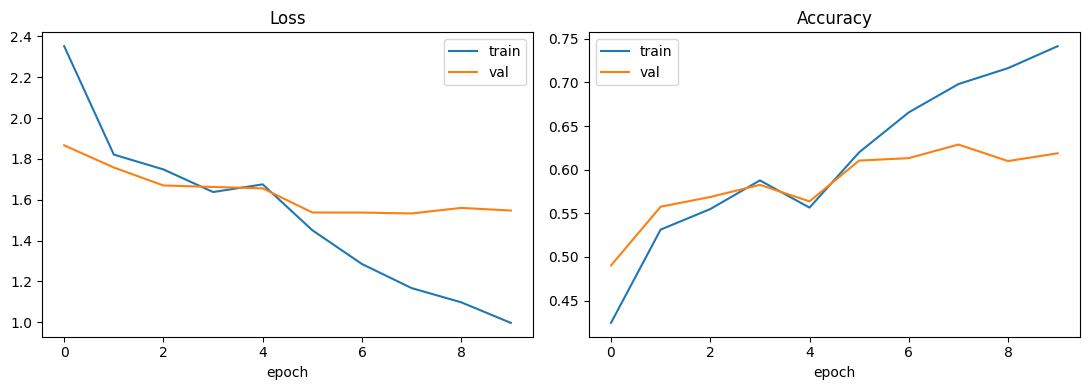

In [6]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Inspect a prediction *(fill the blank)*

For multi-class, the prediction is the class with the **highest** softmax probability.


In [7]:
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

true topic:  3   predicted:  3
true topic: 10   predicted:  1
true topic:  1   predicted: 11
true topic:  4   predicted:  4
true topic:  4   predicted: 13


## Task 6 — Short questions *(write answers here)*

1. What are the **three** differences between this model and Example A (output units, activation,
   loss)?
2. Why `sparse_categorical_crossentropy` here instead of `categorical_crossentropy`? (Hint: are
   the labels one-hot or integers?)
3. The Embedding and Bidirectional LSTM layers are **identical** to Example A. What does that tell
   you about reusing a sequence backbone across tasks?
4. Multi-class accuracy (~68%) is lower than IMDB (~87%). Give one reason why 46-way is harder than
   2-way.

> **Your answers:** 1. … 2. … 3. … 4. …


Task 6 — Short Questions
1. Reuters has 46 output neurons, softmax activation and sparse categorical crossentropy loss, whereas IMDB has 1 output neuron, sigmoid activation and binary crossentropy loss.

2. We use sparse categorical crossentropy because our labels are in integer form (0–45) and not one-hot encoded.

3. It tells us that we can reuse the same Embedding and Bidirectional LSTM layers for different text classification tasks. We only need to change the output layer according to the task.

4. 46-way classification is harder because the model has to predict one category out of 46 instead of just two. So there are more chances of making mistakes.